# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [3]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [4]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [5]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [6]:
df = pd.read_csv(PLIK_LODZ, sep=";")

display(df.head())
print("wymiary:", df.shape)
print(df.dtypes)
print("nazwy kolumn:", list(df.columns))

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


wymiary: (65, 4)
name         str
rok        int64
wartość    int64
zmienna      str
dtype: object
nazwy kolumn: ['name', 'rok', 'wartość', 'zmienna']


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* …

Separatorem jest średnik ";"

Kolumna wartość ma typ liczbowy (int64)

Nazwy kolumn z polskimi znakami wczytały się poprawnie: plik jest w UTF-8


## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [7]:
print(df["zmienna"].value_counts())
print("\nlata:", df["rok"].min(), "-", df["rok"].max(), "| liczba lat:", df["rok"].nunique())

szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka = szeroka[["uczelnie", "ogółem", "kobiety", "mężczyźni", "absolwenci ogółem"]]  # czytelna kolejność
szeroka.columns.name = None
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64

lata: 2012 - 2024 | liczba lat: 13


,uczelnie,ogółem,kobiety,mężczyźni,absolwenci ogółem
rok,,,,,
2012,22,91546,55265,36281,24825
2013,22,83471,50007,33464,22590
2014,23,80676,48220,32456,21343
2015,21,76353,45584,30769,19835
2016,20,73961,44053,29908,17662
2017,22,72019,42990,29029,19281
2018,20,65565,39312,26253,17046
2019,19,64443,38146,26297,15819
2020,18,65325,39170,26155,14082


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [8]:
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
print(roznica)
print("\nwszystkie różnice równe 0:", (roznica == 0).all())


rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64

wszystkie różnice równe 0: True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [9]:
display(szeroka.describe())

zmiana = (szeroka.loc[2024] / szeroka.loc[2012] - 1) * 100
print("zmiana 2012 -> 2024 [%]:")
print(zmiana.round(1))

szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
display(szeroka[["udzial_kobiet", "studenci_na_uczelnie"]])

,uczelnie,ogółem,kobiety,mężczyźni,absolwenci ogółem
count,13.00,13.00,13.00,13.00,13.00
mean,19.54,71804.85,43010.92,28793.92,17780.54
std,2.44,8900.65,5391.05,3524.63,3522.40
min,15.00,64272.00,38146.00,25710.00,14082.00
25%,18.00,65297.00,39170.00,26049.00,14756.00
50%,20.00,66002.00,39958.00,26297.00,17046.00
75%,22.00,76353.00,45584.00,30769.00,19835.00
max,23.00,91546.00,55265.00,36281.00,24825.00


zmiana 2012 -> 2024 [%]:
uczelnie            -31.80
ogółem              -29.80
kobiety             -30.20
mężczyźni           -29.10
absolwenci ogółem   -41.30
dtype: float64


,udzial_kobiet,studenci_na_uczelnie
rok,,
2012,0.60,4161.18
2013,0.60,3794.14
2014,0.60,3507.65
2015,0.60,3635.86
2016,0.60,3698.05
2017,0.60,3273.59
2018,0.60,3278.25
2019,0.59,3391.74
2020,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

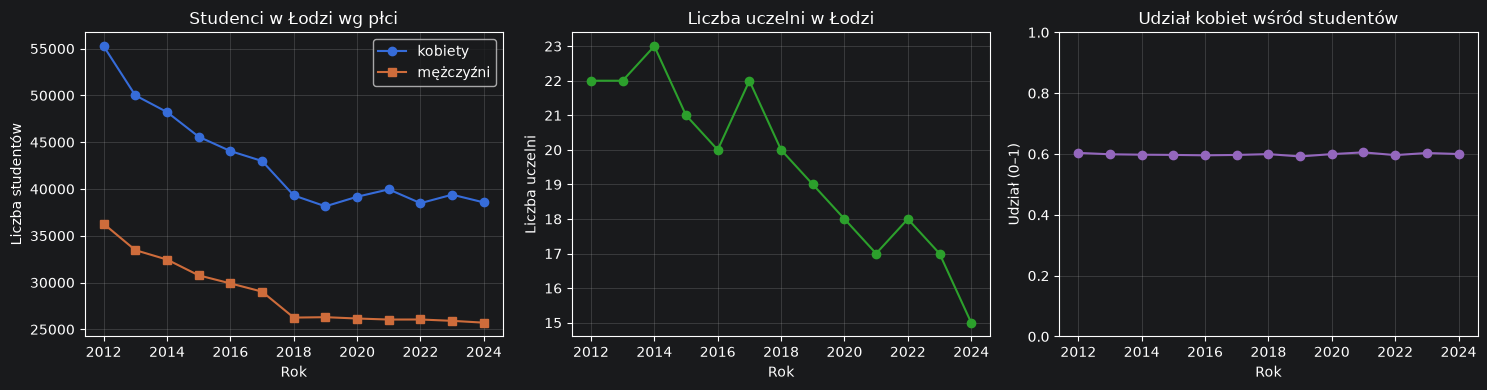

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(szeroka.index, szeroka["kobiety"], marker="o", label="kobiety")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], marker="s", label="mężczyźni")
axes[0].set_title("Studenci w Łodzi wg płci")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba studentów")
axes[0].legend()

axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o", color="tab:green")
axes[1].set_title("Liczba uczelni w Łodzi")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")

axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", color="tab:purple")
axes[2].set_ylim(0, 1)
axes[2].set_title("Udział kobiet wśród studentów")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział (0–1)")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* …

Liczba studentów spadła, spadek był największy do 2018, liczba uczelni zmalała z 22 do 15. Udział kobiet pozostał praktycznie stały.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** rodziny-ktorym-na-podstawie-decyzji-przyznano-pomoc-wg-przyczyn · **link:** https://otwarte.miasto.lodz.pl/wp-content/uploads/2026/01/rodziny-ktorym-na-podstawie-decyzji-przyznano-pomoc-wg-przyczyn.csv · **data pobrania:** 25.10.2026

Problemy z surowymi danymi: kolumna rok jest tekstowa przez spacje w latach, występuje 7 pustych kolumn, niektóre nazwy przyczyn mają zbędne tabulatory, a jedna nazwa jest za długa. Poprawiamy to przez odpowiednie wczytanie danych i oczyszczenie nazw.

In [11]:
PLIK_POMOC = "rodziny-ktorym-na-podstawie-decyzji-przyznano-pomoc-wg-przyczyn.csv"
upewnij_sie_ze_jest(PLIK_POMOC)

with open(PLIK_POMOC, encoding="utf-8") as f:
    for _ in range(3):
        print(repr(f.readline()))

surowe = pd.read_csv(PLIK_POMOC, sep=";")
print("\nwymiary:", surowe.shape)
print(surowe.dtypes)
print("\nbraki danych:\n", surowe.isna().sum())
print("\nunikalne wartości w kolumnie rok:", surowe["rok"].unique().tolist())
print("\nunikalne zmienne (repr pokazuje tabulatory):")
for z in surowe["zmienne"].unique():
    print("  ", repr(z))

Plik rodziny-ktorym-na-podstawie-decyzji-przyznano-pomoc-wg-przyczyn.csv jest na miejscu.
'\ufeffname;rok;wartość;zmienne;;;;;;;\n'
'Rodziny, którym na podstawie decyzji przyznano pomoc wg przyczyn;2 014;14055;ubóstwo;;;;;;;\n'
'Rodziny, którym na podstawie decyzji przyznano pomoc wg przyczyn;2 015;14348;ubóstwo;;;;;;;\n'

wymiary: (121, 11)
name               str
rok                str
wartość          int64
zmienne            str
Unnamed: 4     float64
Unnamed: 5     float64
Unnamed: 6     float64
Unnamed: 7     float64
Unnamed: 8     float64
Unnamed: 9     float64
Unnamed: 10    float64
dtype: object

braki danych:
 name             0
rok              0
wartość          0
zmienne          0
Unnamed: 4     121
Unnamed: 5     121
Unnamed: 6     121
Unnamed: 7     121
Unnamed: 8     121
Unnamed: 9     121
Unnamed: 10    121
dtype: int64

unikalne wartości w kolumnie rok: ['2 014', '2 015', '2 016', '2 017', '2 018', '2 019', '2 020', '2 021', '2 022', '2 023', '2024', '2014', '2015', '

name           str
rok          int64
wartość      int64
zmienne        str
przyczyna      str
dtype: object

braki: 0 | duplikaty (rok, przyczyna): 0
lata: 2014 - 2024 | liczba przyczyn: 11
wierszy na przyczynę (powinno być 11 dla każdej): [11]


,długotrwała lub ciężka choroba,niepełnosprawność,bezrobocie,ubóstwo,bezradność opiekuńczo-wychowawcza,alkoholizm,bezdomność,potrzeba ochrony macierzyństwa,narkomania,przemoc w rodzinie,sieroctwo
rok,,,,,,,,,,,
2014,12160,9457,15486,14055,4447,1162,681,1971,130,103,23
2015,12049,9150,13703,14348,3985,1136,680,1729,113,116,25
2016,12009,8812,12039,12003,3416,1062,653,1507,119,108,23
2017,11601,8339,10277,6810,2872,1066,625,1258,112,96,12
2018,10779,7416,8541,5471,2461,962,630,1104,116,92,9
2019,10384,6785,7373,4707,2116,916,578,990,103,105,7
2020,9661,6076,6776,4050,1879,873,579,879,108,100,8
2021,8927,5443,6116,3578,1654,877,520,713,130,97,7
2022,8413,5018,5113,4024,1377,874,548,588,134,81,12


,mean,std,min,50%,max
długotrwała lub ciężka choroba,10325.00,1481.37,8413.00,10384.00,12160.00
niepełnosprawność,6935.64,1791.07,4646.00,6785.00,9457.00
bezrobocie,8606.91,3788.01,4059.00,7373.00,15486.00
ubóstwo,6924.45,4355.97,3080.00,4707.00,14348.00
bezradność opiekuńczo-wychowawcza,2446.73,1099.81,1272.00,2116.00,4447.00
alkoholizm,1012.73,113.74,873.00,1062.00,1162.00
bezdomność,636.09,94.82,520.00,627.00,876.00
potrzeba ochrony macierzyństwa,1079.09,488.74,519.00,990.00,1971.00
narkomania,133.00,34.18,103.00,119.00,206.00
przemoc w rodzinie,101.73,10.37,81.00,103.00,117.00


suma wskazań w 2014: 59675 -> 2024: 24096


,zmiana 2014→2024 [%],udział 2014 [%],udział 2024 [%]
długotrwała lub ciężka choroba,-30.30,20.38,35.18
niepełnosprawność,-50.87,15.85,19.28
bezrobocie,-73.79,25.95,16.85
ubóstwo,-78.09,23.55,12.78
bezradność opiekuńczo-wychowawcza,-71.40,7.45,5.28
alkoholizm,-5.42,1.95,4.56
bezdomność,-7.93,1.14,2.60
potrzeba ochrony macierzyństwa,-73.67,3.30,2.15
narkomania,58.46,0.22,0.85
przemoc w rodzinie,0.97,0.17,0.43



największe spadki rok do roku [%]:
 rok             
2017  sieroctwo    -47.80
      ubóstwo      -43.30
2024  bezdomność   -28.40
2018  sieroctwo    -25.00
dtype: float64

największe wzrosty rok do roku [%]:
 rok                     
2023  narkomania           43.30
      przemoc w rodzinie   44.40
      bezdomność           59.90
2022  sieroctwo            71.40
dtype: float64


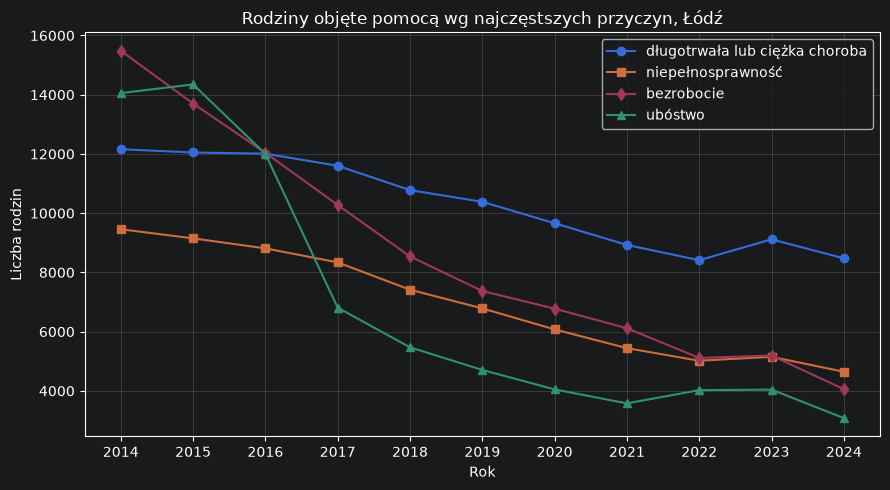

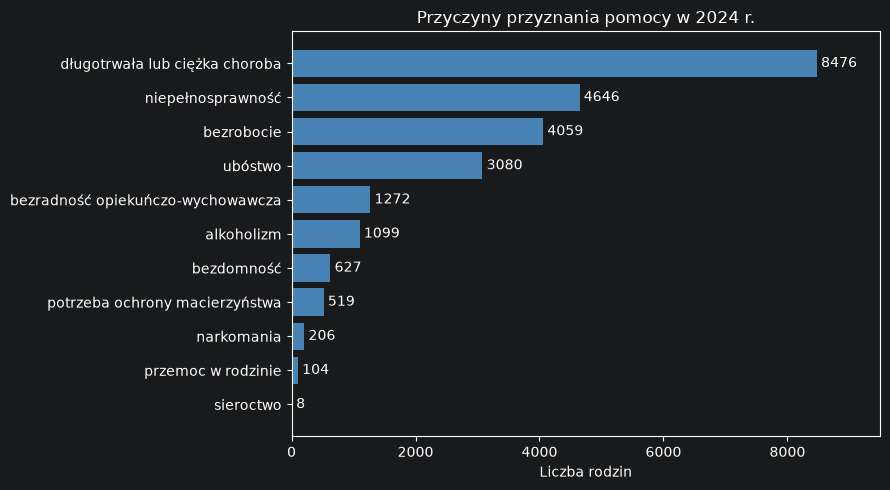

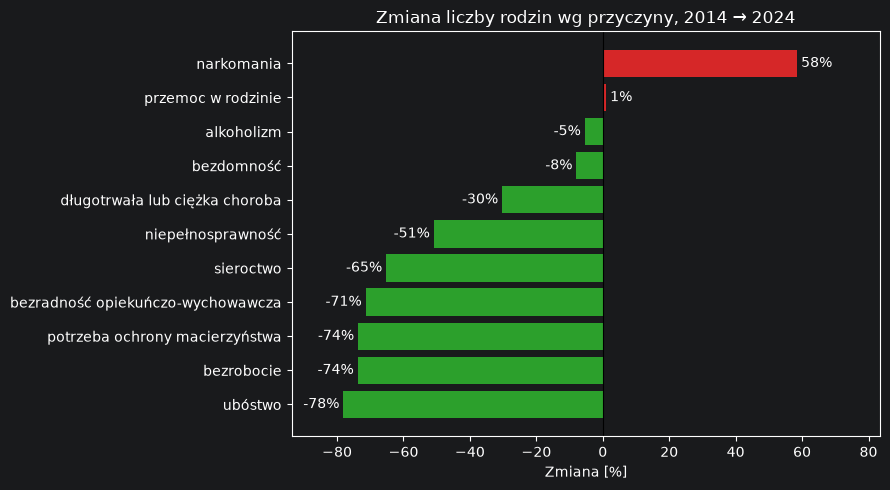

In [12]:
pomoc = pd.read_csv(
    PLIK_POMOC, sep=";",
    usecols=["name", "rok", "wartość", "zmienne"],
    thousands=" ",
)
pomoc["zmienne"] = pomoc["zmienne"].str.strip()

pomoc["przyczyna"] = pomoc["zmienne"].replace({
    "bezradność w sprawach opiekuńczo-wychowawczych i prowadzenia gospodarstwa domowego":
        "bezradność opiekuńczo-wychowawcza"
})

print(pomoc.dtypes)
print("\nbraki:", pomoc.isna().sum().sum(), "| duplikaty (rok, przyczyna):", pomoc.duplicated(["rok", "przyczyna"]).sum())
print("lata:", pomoc["rok"].min(), "-", pomoc["rok"].max(), "| liczba przyczyn:", pomoc["przyczyna"].nunique())
print("wierszy na przyczynę (powinno być 11 dla każdej):", pomoc.groupby("przyczyna").size().unique().tolist())
pomoc.head()

szeroka_pomoc = pomoc.pivot(index="rok", columns="przyczyna", values="wartość")
szeroka_pomoc.columns.name = None
szeroka_pomoc = szeroka_pomoc[szeroka_pomoc.loc[2024].sort_values(ascending=False).index]
display(szeroka_pomoc)

display(szeroka_pomoc.describe().T[["mean", "std", "min", "50%", "max"]])

zmiana = ((szeroka_pomoc.loc[2024] / szeroka_pomoc.loc[2014] - 1) * 100).sort_values()
udzial = szeroka_pomoc.div(szeroka_pomoc.sum(axis=1), axis=0) * 100
print("suma wskazań w 2014:", szeroka_pomoc.loc[2014].sum(), "-> 2024:", szeroka_pomoc.loc[2024].sum())
display(pd.DataFrame({"zmiana 2014→2024 [%]": zmiana,
                      "udział 2014 [%]": udzial.loc[2014],
                      "udział 2024 [%]": udzial.loc[2024]}).sort_values("udział 2024 [%]", ascending=False))

rok_do_roku = (szeroka_pomoc.pct_change() * 100).stack().dropna().sort_values()
print("\nnajwiększe spadki rok do roku [%]:\n", rok_do_roku.head(4).round(1))
print("\nnajwiększe wzrosty rok do roku [%]:\n", rok_do_roku.tail(4).round(1))

fig, ax = plt.subplots(figsize=(9, 5))
for przyczyna, znacznik in zip(["długotrwała lub ciężka choroba", "niepełnosprawność", "bezrobocie", "ubóstwo"], "osd^"):
    ax.plot(szeroka_pomoc.index, szeroka_pomoc[przyczyna], marker=znacznik, label=przyczyna)
ax.set_title("Rodziny objęte pomocą wg najczęstszych przyczyn, Łódź")
ax.set_xlabel("Rok")
ax.set_ylabel("Liczba rodzin")
ax.set_xticks(szeroka_pomoc.index)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
dane2024 = szeroka_pomoc.loc[2024].sort_values()
slupki = ax.barh(dane2024.index, dane2024.values, color="steelblue")
ax.bar_label(slupki, padding=3)
ax.set_title("Przyczyny przyznania pomocy w 2024 r.")
ax.set_xlabel("Liczba rodzin")
ax.set_xlim(0, dane2024.max() * 1.12)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
kolory = ["tab:green" if z < 0 else "tab:red" for z in zmiana.values]
slupki = ax.barh(zmiana.index, zmiana.values, color=kolory)
ax.bar_label(slupki, fmt="%.0f%%", padding=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Zmiana liczby rodzin wg przyczyny, 2014 → 2024")
ax.set_xlabel("Zmiana [%]")
ax.set_xlim(zmiana.min() * 1.2, zmiana.max() + 25)
plt.tight_layout()
plt.show()

✍️ **Wnioski:** …

W latach 2014–2024 liczba wskazań przyczyn pomocy spadła o około 60%. Najbardziej zmniejszyły się ubóstwo i bezrobocie, a w 2024 r. najczęstszą przyczyną pomocy była długotrwała lub ciężka choroba. Wzrosła natomiast liczba wskazań narkomanii. Duży spadek ubóstwa w 2017 r. może wynikać ze zmiany sposobu liczenia danych, ale nie da się tego potwierdzić na ich podstawie.
Jedna rodzina mogła mieć kilka przyczyn pomocy, więc liczba wskazań nie oznacza liczby rodzin.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [13]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


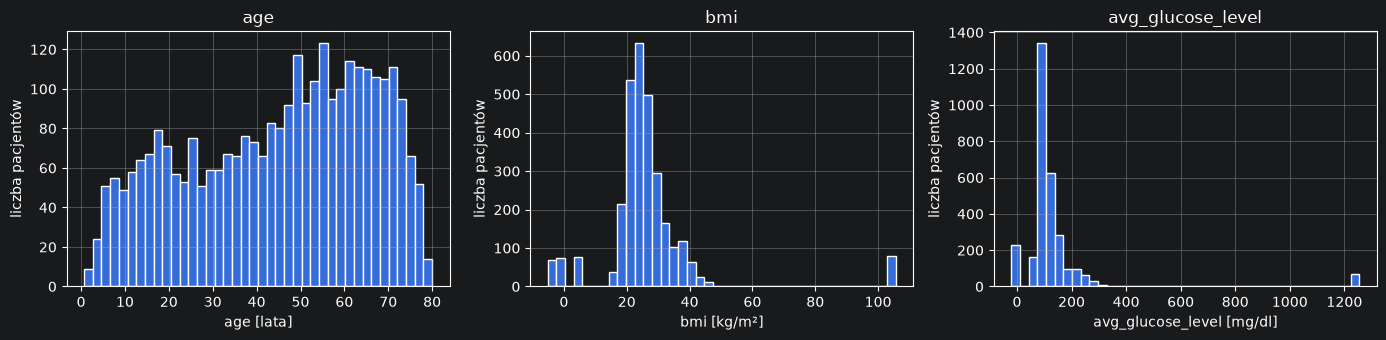

In [14]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

display(pacjenci[LICZBOWE].describe())

axs = pacjenci[LICZBOWE].hist(bins=40, figsize=(14, 3.5), layout=(1, 3), edgecolor="white")
for ax, nazwa, jedn in zip(axs.ravel(), LICZBOWE, ["lata", "kg/m²", "mg/dl"]):
    ax.set_xlabel(f"{nazwa} [{jedn}]")
    ax.set_ylabel("liczba pacjentów")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* …

Wiek jest w normie (0,67–80 lat). Nieprawidłowe są wartości BMI (−5,2 i 105,6) oraz glukozy (−21,4 i 1254,6 mg/dl). Błędne dane zawyżają odchylenie standardowe glukozy i sprawiają, że średnia (134) jest wyższa od mediany (101).

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [15]:
zle_bmi = pacjenci["bmi"].notna() & ~pacjenci["bmi"].between(10, 60)
zla_glukoza = pacjenci["avg_glucose_level"].notna() & ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = pacjenci["age"].notna() & ~pacjenci["age"].between(0, 120)

print("niemożliwe BMI:     ", zle_bmi.sum())
print("niemożliwa glukoza: ", zla_glukoza.sum())
print("niemożliwy wiek:    ", zly_wiek.sum())
print("pacjentów z co najmniej jedną niemożliwą wartością:", (zle_bmi | zla_glukoza | zly_wiek).sum())

pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan
print("\nbraki po zamianie:\n", pacjenci[LICZBOWE].isna().sum())

niemożliwe BMI:      300
niemożliwa glukoza:  300
niemożliwy wiek:     0
pacjentów z co najmniej jedną niemożliwą wartością: 560

braki po zamianie:
 age                    0
bmi                  300
avg_glucose_level    300
dtype: int64


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


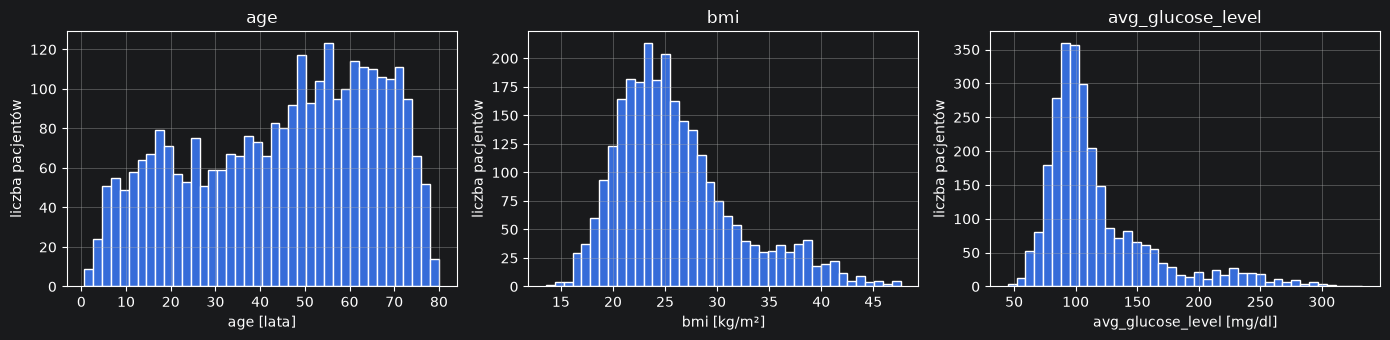

In [16]:
display(pacjenci[LICZBOWE].describe())

axs = pacjenci[LICZBOWE].hist(bins=40, figsize=(14, 3.5), layout=(1, 3), edgecolor="white")
for ax, nazwa, jedn in zip(axs.ravel(), LICZBOWE, ["lata", "kg/m²", "mg/dl"]):
    ax.set_xlabel(f"{nazwa} [{jedn}]")
    ax.set_ylabel("liczba pacjentów")
plt.tight_layout()
plt.show()

Co się zmieniło? Po usunięciu błędnych wartości BMI i glukoza mają realistyczne zakresy. Średnia glukozy spadła z 134 do 116,8, a jej odchylenie standardowe ze 181,3 do 44,5. Histogramy lepiej pokazują rozkład danych, choć glukoza nadal ma więcej niskich niż wysokich wyników. Wiek pozostał bez zmian.

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

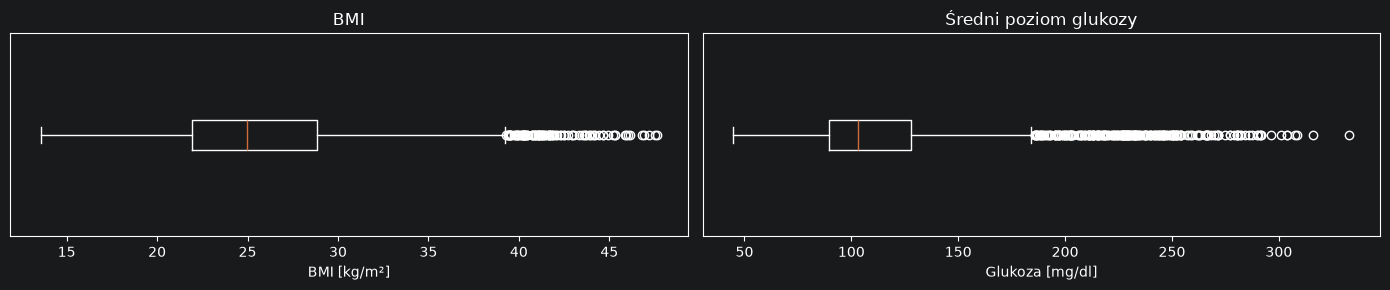

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal")
axes[0].set_title("BMI")
axes[0].set_xlabel("BMI [kg/m²]")
axes[0].set_yticks([])

axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal")
axes[1].set_title("Średni poziom glukozy")
axes[1].set_xlabel("Glukoza [mg/dl]")
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

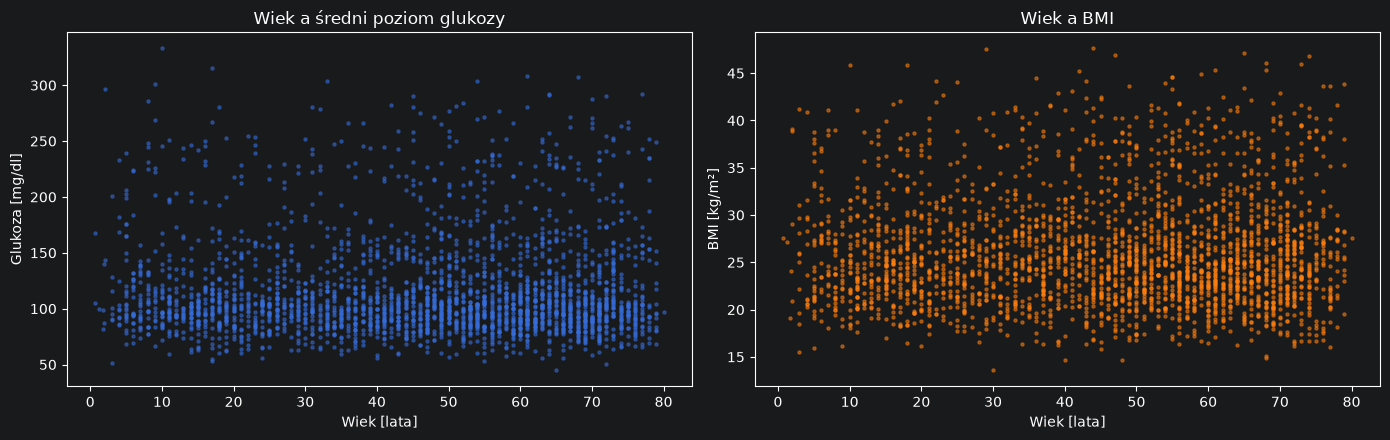

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], s=5, alpha=0.5)
axes[0].set_title("Wiek a średni poziom glukozy")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Glukoza [mg/dl]")

axes[1].scatter(pacjenci["age"], pacjenci["bmi"], s=5, alpha=0.5, color="tab:orange")
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("Wiek [lata]")
axes[1].set_ylabel("BMI [kg/m²]")

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* …

Glukoza ma więcej wartości odstających niż BMI (235 vs 100). W obu rozkładach odstające wartości są po prawej stronie. Wysoka glukoza występuje w różnym wieku i nie musi oznaczać błędu. Wynik 333 mg/dl u 10-latka może być prawdziwy, dlatego nie usuwamy go automatycznie. Pamiętamy, że dane są syntetyczne.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [19]:
def maska_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    zm = 0.6745 * (s - med) / mad
    return zm.abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [20]:
metody = {
    "IQR 1,5": lambda s: maska_iqr(s, 1.5),
    "IQR 3":   lambda s: maska_iqr(s, 3),
    "z-score": maska_z,
    "MAD":     maska_mad,
}
porownanie = pd.DataFrame(
    {nazwa: {kol: int(f(pacjenci[kol]).sum()) for kol in LICZBOWE} for nazwa, f in metody.items()}
)
porownanie["skośność"] = [pacjenci[kol].skew() for kol in LICZBOWE]
porownanie

,"IQR 1,5",IQR 3,z-score,MAD,skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* …

Glukoza ma rozkład prawoskośny, dlatego różne metody wykrywają różną liczbę wartości odstających: IQR 1,5 – 235, MAD – 223, z-score – 62, a IQR 3 – 81. Z-score wykrywa mniej wartości, ponieważ skrajne wyniki zawyżają średnią i odchylenie standardowe. Wiek nie ma wartości odstających według tych metod. Metodę należy dobrać do rozkładu danych.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

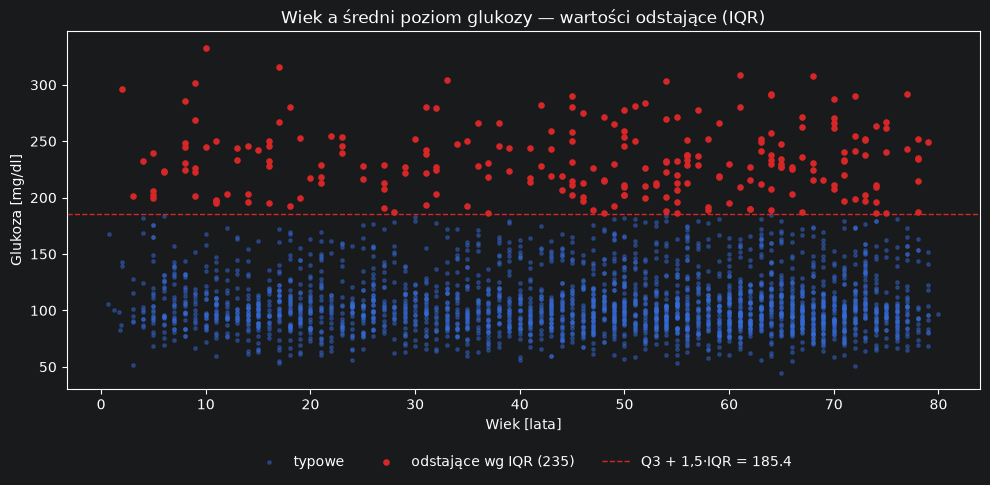

punkty nad linią: 235 | poza wąsem na boxplocie: 235 | maska_iqr: 235


In [21]:
glukoza = pacjenci["avg_glucose_level"]
q1, q3 = glukoza.quantile([0.25, 0.75])
iqr = q3 - q1
gorna = q3 + 1.5 * iqr
odstaje = maska_iqr(glukoza)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(pacjenci.loc[~odstaje, "age"], glukoza[~odstaje], s=6, alpha=0.4, label="typowe")
ax.scatter(pacjenci.loc[odstaje, "age"], glukoza[odstaje], s=14, color="tab:red",
           label=f"odstające wg IQR ({odstaje.sum()})")
ax.axhline(gorna, color="tab:red", linestyle="--", linewidth=1, label=f"Q3 + 1,5·IQR = {gorna:.1f}")
ax.set_title("Wiek a średni poziom glukozy — wartości odstające (IQR)")
ax.set_xlabel("Wiek [lata]")
ax.set_ylabel("Glukoza [mg/dl]")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots()
bp = ax2.boxplot(glukoza.dropna(), orientation="horizontal")
poza_wasami = len(bp["fliers"][0].get_ydata())
plt.close(fig2)
print(f"punkty nad linią: {(glukoza > gorna).sum()} | poza wąsem na boxplocie: {poza_wasami} | maska_iqr: {odstaje.sum()}")

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

,liczba,udary,odsetek udarów [%]
glukoza odstająca,235,51,21.70
pozostali,2465,520,21.10


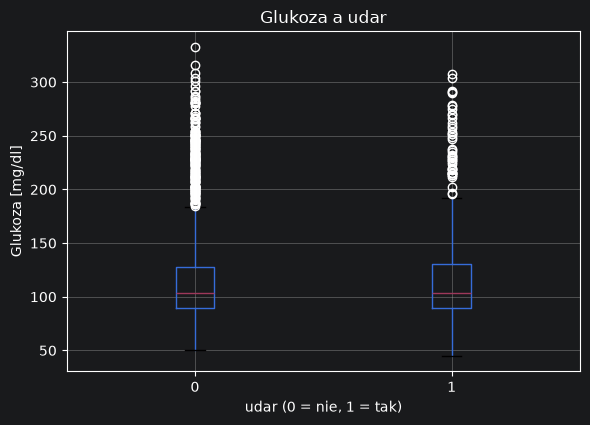

In [22]:
ma_glukoze = pacjenci["avg_glucose_level"].notna()
grupa = np.where(odstaje, "glukoza odstająca", "pozostali")
udary = (pacjenci.loc[ma_glukoze].groupby(grupa[ma_glukoze])["stroke"]
         .agg(liczba="size", udary="sum", odsetek="mean"))
udary["odsetek"] = udary["odsetek"] * 100
display(udary.rename(columns={"odsetek": "odsetek udarów [%]"}))

fig, ax = plt.subplots(figsize=(6, 4.5))
pacjenci.boxplot(column="avg_glucose_level", by="stroke", ax=ax)
ax.set_title("Glukoza a udar")
fig.suptitle("")
ax.set_xlabel("udar (0 = nie, 1 = tak)")
ax.set_ylabel("Glukoza [mg/dl]")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie należy usuwać tych wartości, ponieważ mieszczą się w możliwym zakresie i nie muszą być błędami. Usunięcie około 9% pacjentów zmniejszyłoby próbę i utrudniło modelowi przewidywanie wyników dla podobnych osób. W tych danych odsetek udarów jest podobny w obu grupach, więc nie widać wyraźnego związku wysokiej glukozy z udarem. Wartości odstające lepiej pozostawić lub zastosować logarytm, dodatkową flagę albo metodę odporną na skrajne wyniki.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [23]:
display(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))

dziecko_pali = ((pacjenci["work_type"] == "children")
                & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"]))
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")
print("dziecko pali:", dziecko_pali.sum(), "| maluch-student:", maluch_student.sum())

kolumny_podglad = ["patient_id", "age", "work_type", "smoking_status", "stroke"]
display(pacjenci.loc[dziecko_pali | maluch_student, kolumny_podglad].sort_values("age"))

smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


dziecko pali: 15 | maluch-student: 1


,patient_id,age,work_type,smoking_status,stroke
52,A582477,1.80,student,formerly smoked,0
361,A843508,2.00,children,smokes,0
578,A161666,3.00,children,smokes,0
797,A427670,5.00,children,smokes,0
942,A929594,8.00,children,smokes,0
782,A383975,9.00,children,smokes,0
111,A678646,9.00,children,smokes,0
600,A623587,10.00,children,smokes,0
2389,A367897,11.00,children,smokes,0
987,A105353,11.00,children,smokes,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* …

IQR i z-score nie wykryją tych przypadków, ponieważ analizują każdą zmienną osobno. Wiek dzieci jest prawidłowy, a kategorie „children” i „smokes” same w sobie nie są błędne. Problemem jest ich połączenie. Takie przypadki można wykryć za pomocą reguł opartych na wiedzy dziedzinowej. Znaleziono 15 palących dzieci i 1 małe dziecko ze statusem „student”, czyli łącznie 16 pacjentów.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [24]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=X.shape[1])

print(f"pacjentów bez braków: {len(X)}, próg chi2(0,99; df={X.shape[1]}) = {prog:.2f}")
odl = d2 > prog
print("odległość euklidesowa — odstających:", odl.sum())

print("\ncecha o największym udziale w d²:")
print((Z[odl] ** 2).idxmax(axis=1).value_counts())

pacjentów bez braków: 2440, próg chi2(0,99; df=3) = 11.34
odległość euklidesowa — odstających: 73

cecha o największym udziale w d²:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

skośność glukozy: 1.78 -> po logarytmie: 0.89
odstających: 73 (surowe) -> 31 (po logarytmie glukozy)


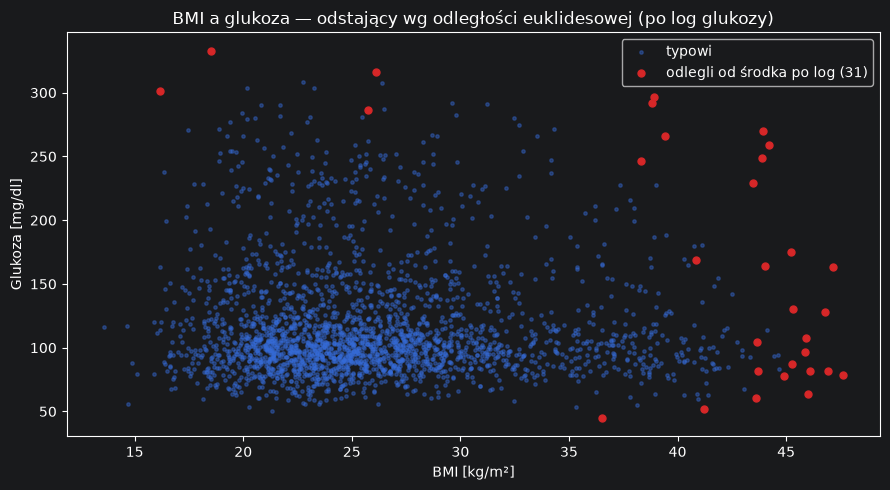

In [25]:
X_log = X.assign(avg_glucose_level=np.log(X["avg_glucose_level"]))
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odl_log = d2_log > prog

print(f"skośność glukozy: {X['avg_glucose_level'].skew():.2f} -> po logarytmie: {X_log['avg_glucose_level'].skew():.2f}")
print(f"odstających: {odl.sum()} (surowe) -> {odl_log.sum()} (po logarytmie glukozy)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X.loc[~odl_log, "bmi"], X.loc[~odl_log, "avg_glucose_level"], s=6, alpha=0.4, label="typowi")
ax.scatter(X.loc[odl_log, "bmi"], X.loc[odl_log, "avg_glucose_level"], s=25, color="tab:red",
           label=f"odlegli od środka po log ({odl_log.sum()})")
ax.set_title("BMI a glukoza — odstający wg odległości euklidesowej (po log glukozy)")
ax.set_xlabel("BMI [kg/m²]")
ax.set_ylabel("Glukoza [mg/dl]")
ax.legend()
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* …

Mahalanobis praktycznie nic tu nie zmienia, ponieważ korelacje między cechami są bardzo słabe (0,01–0,02). Dlatego obie metody wykrywają po 31 pacjentów, z czego 30 tych samych, a korelacja wyników wynosi 0,9997. Mahalanobis jest bardziej przydatny, gdy cechy są skorelowane i trzeba wykryć punkty, które odbiegają od wspólnego trendu.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [26]:
# TODO (dla chętnych)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [27]:
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = zle_bmi | zla_glukoza | zly_wiek
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"]).fillna(False)
flagi["nielogiczna_kategoria"] = dziecko_pali | maluch_student
flagi["odlegly_od_srodka"] = odl_log.reindex(oryginal.index, fill_value=False)   # bez obliczonej odległości -> False

print("liczba pacjentów z daną flagą:")
print(flagi.sum())
print("\nco najmniej jedna flaga:", flagi.any(axis=1).sum(), "z", len(flagi))
print("żadnej flagi:", (~flagi.any(axis=1)).sum())
flagi.head()

liczba pacjentów z daną flagą:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64

co najmniej jedna flaga: 806 z 3000
żadnej flagi: 2194


,niemozliwa_wartosc,glukoza_iqr,nielogiczna_kategoria,odlegly_od_srodka
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN | To błędy danych, które zniekształcają statystyki, więc należy je oznaczyć jako brakujące. |
| wysoka glukoza (IQR) | zostawić + log (lub flaga) | Są to możliwe wartości, których usunięcie oznaczałoby utratę ważnych informacji |
| nielogiczne kategorie | usunąć wiersze | Nie wiadomo, która informacja jest błędna, a usunięcie 16 z 3000 rekordów oznacza niewielką strate |
| odlegli od środka | flaga / zostawić | Nietypowe kombinacje cech nie muszą być błędami, dlatego warto je zachować i oznaczyć |